<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-12/lab-070a-xxz-phase-diagram.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 070a. Variational phase diagram of the XXZ chain in a transverse field

A variational circuit is usually tested at one point of a model's parameter space. A ground state, however, changes character across a phase diagram. It can be close to a product state, a superposition of two ordered configurations or a strongly entangled critical state, and an ansatz that works in one region can fail in another. We study this on the XXZ spin chain of $N=8$ qubits in a magnetic field along $x$, whose ground state changes between ferromagnetic, antiferromagnetic, critical and field-polarised behaviour as the anisotropy $\Delta$ and the field $h_x$ vary.

We first compute the exact ground state on a fine grid of $(\Delta,h_x)$ by a Lanczos diagonalisation that never stores the Hamiltonian as a matrix, and map its entanglement entropy and three magnetisations. We then train two circuit ansätze on a coarser grid with the variational quantum eigensolver (VQE) [1], the hardware-efficient ansatz [2] and a Hamiltonian-variational ansatz with independent angles, built from the terms of the model [3, 4]. For every grid point we compare the trained state with the exact one by its energy error, its fidelity and its entanglement entropy, and locate where each ansatz fails.

All results are exact state-vector simulations with exact gradients, whereas a quantum device would estimate every energy from measured bit strings. Sections 2 to 7 form the core route, which ends with the maps of the ansatz errors, and Section 8 can be finished at home. The flag `RETRAIN` in the first code cell selects the mode. With `RETRAIN = True` the notebook diagonalises and trains everything, which took about six minutes on a shared laptop CPU and produced the stored outputs. With the default `RETRAIN = False` it loads the saved scan and redraws every figure in about ten seconds.

## 1. Double-precision arithmetic

We work in double precision, `float64` and `complex128`, so that the identities checked by `assert` hold to about $10^{-10}$. JAX computes the Hamiltonian, the circuits and their gradients on the CPU, SciPy provides an independent Lanczos check, and Matplotlib draws the maps. Every random seed is fixed.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # small dense calculations; the CPU avoids GPU memory allocation
import json, time, itertools
from pathlib import Path
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh, LinearOperator
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)
CDTYPE = jnp.complex128
TOL = 1e-10
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "legend.fontsize": 10, "figure.figsize": (4.8, 3.2), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts: the PDFs embed cleanly in LaTeX
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
def panel(ax, letter):
    ax.text(0.03, 0.96, f"({letter})", transform=ax.transAxes, ha="left", va="top", fontsize=11, zorder=10,
            bbox=dict(fc="white", ec="none", pad=1.0, alpha=0.85))
def sci(x, digits=1):
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
RETRAIN = False   # True: diagonalise and train (several minutes); False: load the saved scan and redraw
SCAN = RES / "lab070a_scan.npz"
COL = {"HEA": "#005CA7", "HVA": "#1B7F36"}   # course palette: HEA blue, HVA with independent angles green
started = time.perf_counter()
NUMBERS = {}
key = jax.random.PRNGKey(700)
print("RETRAIN =", RETRAIN, "| JAX", jax.__version__, "| devices:", jax.devices())

RETRAIN = False | JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. The XXZ chain in a transverse field

The XXZ chain couples neighbouring spins through all three components, with a separate weight $\Delta$ for the $z$ components. In a magnetic field along $x$ its Hamiltonian is
$$\hat{\mathcal H}=J\sum_{i=0}^{N-2}\big(\hat X_i\hat X_{i+1}+\hat Y_i\hat Y_{i+1}+\Delta\,\hat Z_i\hat Z_{i+1}\big)-h_x\sum_{i=0}^{N-1}\hat X_i , \tag{1}$$
for an open chain of $N=8$ qubits with $J=1$. The operator $\hat X\hat X+\hat Y\hat Y=2(|01\rangle\langle10|+|10\rangle\langle01|)$ exchanges a $0$ and a $1$ between neighbours, the term $\Delta\hat Z\hat Z$ adds the energy $+\Delta$ to aligned and $-\Delta$ to anti-aligned neighbours, and the field favours every spin in $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$.

Without the field the Hamiltonian conserves the magnetisation $\sum_i\hat Z_i$, because no term changes the number of bits equal to $1$. The field term flips single bits and breaks this conservation. Equation (1) still commutes with the parity
$$\hat\Pi=\prod_{i=0}^{N-1}\hat X_i , \tag{2}$$
which flips all bits at once, $|b_0\dots b_{N-1}\rangle\to|\bar b_0\dots\bar b_{N-1}\rangle$ with $\bar b=1-b$. Every eigenstate therefore has parity $+1$ or $-1$, and the exact ground state lies in one of the two sectors.

We choose a transverse field, because a longitudinal field $-h_z\sum_i\hat Z_i$ commutes with $\sum_i\hat Z_i$ and keeps the ground state in one magnetisation sector. With a longitudinal field the finite-$N$ phase diagram becomes a staircase of crossings between sectors as $h_z$ grows, with the magnetisation rising in steps. The transverse field mixes the sectors, and the ground state builds its entanglement from superpositions across them, which is a harder test for the ansätze.

The phases of the infinite chain are known for small fields, and on eight sites they appear as smooth crossovers. Their character is visible in the bit strings that dominate the ground state, which the sketch after the list collects.

- For $\Delta<-1$ the coupling favours aligned spins along $z$, a ferromagnet. The dominant bit strings are $00000000$ and $11111111$, and every correlator $\langle\hat Z_i\hat Z_j\rangle$ is close to $+1$.
- For $-1<\Delta<1$ and small $h_x$ the exchange term dominates and the chain is in the XY or Luttinger-liquid phase, a critical phase of one-dimensional systems with gapless excitations and correlations that decay as powers of the distance. The ground state spreads its weight over many bit strings with nearly equal numbers of zeros and ones.
- For $\Delta>1$ the coupling favours anti-aligned neighbours along $z$, the Néel antiferromagnet. The dominant bit strings are $01010101$ and $10101010$, and $\langle\hat Z_i\hat Z_{i+1}\rangle$ is close to $-1$.
- At large $h_x$ every spin turns towards $+x$, and the ground state approaches the product state $|+\rangle^{\otimes N}$, a field-polarised paramagnet. Within our grid the transverse magnetisation reaches about $0.85$ on the ferromagnetic side, while on the antiferromagnetic side it stays near $0.3$ at the largest field.

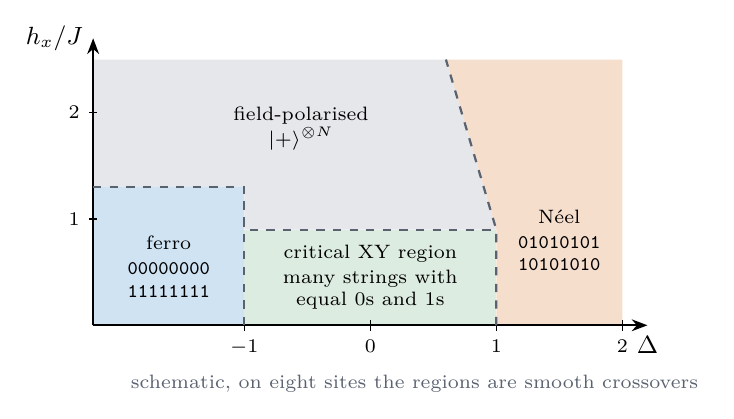

The sketch places the four regimes schematically in the plane of $\Delta$ and $h_x$ with their dominant bit strings, and on eight sites the regions are smooth crossovers.

Measured in the computational basis, the two ordered phases look alike in single spins, since $\hat\Pi\hat Z_i\hat\Pi=-\hat Z_i$ forces $\langle\hat Z_i\rangle=0$ in every parity eigenstate. Their difference lies in the correlations, which the order parameters of Section 4 capture.

## 3. The Hamiltonian without a matrix

The state of $N$ qubits is stored as a rank-$N$ tensor $\psi[b_0,\dots,b_{N-1}]$ with qubit 0 as the most significant bit. We apply equation (1) to this tensor term by term and never form the $2^N\times2^N$ matrix. The $\hat Z\hat Z$ terms are diagonal and multiply each amplitude by $\Delta\sum_iz_iz_{i+1}$ with $z_i=1-2b_i$. The exchange term on bond $(i,i+1)$ moves the amplitude of a bit string with $b_i\neq b_{i+1}$ to the string with both bits flipped, with weight $2$, and gives zero otherwise. The field term $\hat X_i$ reverses the tensor along leg $i$. One application costs of order $N2^N$ operations, against $4^N$ for a dense matrix. The recap cell also defines the gates used by the circuits, a one-qubit gate as a contraction with one leg of the tensor and a two-qubit gate as a contraction with two legs. The code checks the matrix-free Hamiltonian against a sparse Kronecker-product matrix.

In [2]:
# recap: matrix-free state-vector tools on the rank-N tensor psi[b_0, ..., b_{N-1}]
N = 8
SHAPE = (2,) * N
LEGS = tuple(range(N))
BITS = np.array(list(itertools.product([0, 1], repeat=N)))        # row k = bit string of basis index k
SPIN = 1 - 2 * BITS                                                # z_i = +1 for bit 0, -1 for bit 1
ZZ_SUM = jnp.asarray(sum(SPIN[:, i] * SPIN[:, i + 1] for i in range(N - 1)).reshape(SHAPE).astype(float))
EXCHANGE = [jnp.asarray((BITS[:, i] != BITS[:, i + 1]).reshape(SHAPE).astype(float)) for i in range(N - 1)]

def xxz_apply(psi, Delta, hx, J=1.0):
    # equation (1) applied to the rank-N tensor psi
    out = J * Delta * ZZ_SUM * psi
    for i in range(N - 1):
        out = out + 2 * J * EXCHANGE[i] * jnp.flip(psi, axis=(i, i + 1))
    for i in range(N):
        out = out - hx * jnp.flip(psi, axis=i)
    return out
xxz_apply_jit = jax.jit(xxz_apply)

def apply_1q(psi, U, q):
    return jnp.moveaxis(jnp.tensordot(U, psi, axes=([1], [q])), 0, q)
def apply_2q(psi, U, q, r):
    out = jnp.tensordot(U.reshape(2, 2, 2, 2), psi, axes=([2, 3], [q, r]))
    return jnp.moveaxis(out, [0, 1], [q, r])
def rx(t):
    c, s = jnp.cos(t / 2), jnp.sin(t / 2); return jnp.array([[c, -1j * s], [-1j * s, c]], dtype=CDTYPE)
def ry(t):
    c, s = jnp.cos(t / 2), jnp.sin(t / 2); return jnp.array([[c, -s], [s, c]], dtype=CDTYPE)
def rz(t):
    return jnp.diag(jnp.array([jnp.exp(-0.5j * t), jnp.exp(0.5j * t)], dtype=CDTYPE))

# check against the sparse Kronecker-product matrix
I2, X = np.eye(2, dtype=complex), np.array([[0, 1], [1, 0]], dtype=complex)
Y, Z = np.array([[0, -1j], [1j, 0]]), np.array([[1, 0], [0, -1]], dtype=complex)
def op_on(ops):
    out = sp.identity(1, dtype=complex, format="csr")
    for q in range(N):
        out = sp.kron(out, sp.csr_matrix(ops.get(q, I2)), format="csr")
    return out
def xxz_sparse(Delta, hx):
    bonds = sum(op_on({i: X, i + 1: X}) + op_on({i: Y, i + 1: Y}) + Delta * op_on({i: Z, i + 1: Z}) for i in range(N - 1))
    return (bonds - hx * sum(op_on({i: X}) for i in range(N))).tocsr()
v_r = np.random.default_rng(700).normal(size=2 ** N) + 1j * np.random.default_rng(701).normal(size=2 ** N)
assert np.allclose(np.asarray(xxz_apply_jit(jnp.asarray(v_r).reshape(SHAPE), 0.7, 0.4)).reshape(-1), xxz_sparse(0.7, 0.4) @ v_r, atol=TOL)
print("matrix-free Hamiltonian agrees with the sparse Kronecker-product matrix")

matrix-free Hamiltonian agrees with the sparse Kronecker-product matrix


## 4. Exact ground states and order parameters

The Lanczos method finds the lowest eigenvalue of a Hermitian operator from repeated products with a vector. Starting from a normalised vector $|v_0\rangle$, it builds an orthonormal basis $|v_0\rangle,|v_1\rangle,\dots,|v_{m-1}\rangle$ of the space spanned by $|v_0\rangle,\hat{\mathcal H}|v_0\rangle,\dots,\hat{\mathcal H}^{m-1}|v_0\rangle$, in which $\hat{\mathcal H}$ is a tridiagonal $m\times m$ matrix. The lowest eigenvalue of this small matrix converges to $E_0$ long before $m$ reaches the dimension of the Hilbert space, and the corresponding combination of the basis vectors is the ground state. We write the method in JAX with full reorthogonalisation of the basis and $m=50$, so that `jax.vmap` diagonalises all grid points at once, and check it against SciPy's `eigsh`, which receives the same matrix-free product through a `LinearOperator`. Near degeneracies the convergence slows down, and the few points whose residual $\|\hat{\mathcal H}|\psi\rangle-E|\psi\rangle\|$ exceeds $10^{-8}$ are refined with `eigsh`, started from the Lanczos vector.

The parity (2) splits the problem into two sectors. We apply the projector $(\hat I\pm\hat\Pi)/2$ before and after $\hat{\mathcal H}$, which restricts the Lanczos basis to one sector, and diagonalise each sector separately. The lower of the two energies is $E_0$ with its ground state $|\psi_0\rangle$. The splitting $|E_+-E_-|$ between the lowest even and odd levels bounds the gap from above and becomes very small wherever the ground state is a superposition of two ordered configurations, as in the ferromagnet and the Néel antiferromagnet.

For every state we record the energy per site $E/N$, the half-chain entanglement entropy in bits
$$S_{\rm vN}=-\sum_ks_k^2\log_2s_k^2 , \tag{3}$$
where $s_k$ are the singular values of the $16\times16$ matrix of amplitudes with rows labelled by $b_0\dots b_3$ and columns by $b_4\dots b_7$, and three magnetisations. The transverse magnetisation
$$m_x=\frac1N\sum_{i=0}^{N-1}\langle\hat X_i\rangle \tag{4}$$
measures the polarisation along the field. Since $\langle\hat Z_i\rangle=0$ in every parity eigenstate, the order along $z$ is measured by the parity-invariant root-mean-square magnetisations
$$m_{\rm stag}=\sqrt{\Big\langle\Big(\frac1N\sum_{i=0}^{N-1}(-1)^i\hat Z_i\Big)^2\Big\rangle},\qquad m_z=\sqrt{\Big\langle\Big(\frac1N\sum_{i=0}^{N-1}\hat Z_i\Big)^2\Big\rangle} . \tag{5}$$
In the Néel state $m_{\rm stag}=1$ and $m_z=0$, in the ferromagnet $m_z=1$ and $m_{\rm stag}=0$, and both are small in a state spread evenly over many bit strings. They take the same value in an ordered superposition and in each of its two branches, so they cannot tell a cat state from a symmetry-broken one, which the entropy and the fidelity $F=|\langle\psi_0|\psi\rangle|^2$ can.

In [3]:
KRYLOV = 50
def flip_all(t):
    return jnp.flip(t, axis=LEGS)                     # the parity P reverses every leg

def sector_apply(v, Delta, hx, sign):
    t = v.reshape(SHAPE); t = (t + sign * flip_all(t)) / 2
    out = xxz_apply(t, Delta, hx); out = (out + sign * flip_all(out)) / 2
    return out.reshape(-1)

V_START = jax.random.normal(jax.random.PRNGKey(7000), (KRYLOV + 1, 2 ** N)).astype(CDTYPE)   # start and restart vectors

def lanczos_ground(Delta, hx, sign):
    # lowest eigenpair of H in the parity sector `sign`, Lanczos with full reorthogonalisation
    def project(v):
        t = v.reshape(SHAPE); return ((t + sign * flip_all(t)) / 2).reshape(-1)
    def orthonormalise(w, V):
        for _ in range(2):
            w = w - V.T @ (V.conj() @ w)
        return w, jnp.linalg.norm(w)
    v0 = project(V_START[0]); v0 = v0 / jnp.linalg.norm(v0)
    V = jnp.zeros((KRYLOV, 2 ** N), dtype=CDTYPE).at[0].set(v0)
    def body(j, carry):
        V, a, b = carry
        w = sector_apply(V[j], Delta, hx, sign)
        a = a.at[j].set(jnp.real(jnp.vdot(V[j], w)))
        w, beta = orthonormalise(w, V)
        # an exhausted Krylov space continues with a fresh orthogonal vector and a zero coupling
        fresh, fnorm = orthonormalise(project(V_START[j + 1]), V)
        ok = beta > 1e-9
        V = V.at[j + 1].set(jnp.where(ok, w / jnp.where(ok, beta, 1.0), fresh / fnorm))
        return V, a, b.at[j].set(jnp.where(ok, beta, 0.0))
    V, a, b = jax.lax.fori_loop(0, KRYLOV - 1, body, (V, jnp.zeros(KRYLOV), jnp.zeros(KRYLOV - 1)))
    a = a.at[KRYLOV - 1].set(jnp.real(jnp.vdot(V[-1], sector_apply(V[-1], Delta, hx, sign))))
    T = jnp.diag(a) + jnp.diag(b, 1) + jnp.diag(b, -1)
    w, y = jnp.linalg.eigh(T)
    psi = V.T @ y[:, 0].astype(CDTYPE)
    psi = psi / jnp.linalg.norm(psi)
    residual = jnp.linalg.norm(sector_apply(psi, Delta, hx, sign) - w[0] * psi)
    return w[0], psi, residual

def observables(psi, Delta, hx):
    # E, m_x (4), m_stag and m_z (5), S_vN (3) of a normalised state vector
    t = psi.reshape(SHAPE)
    E = jnp.real(jnp.vdot(t, xxz_apply(t, Delta, hx)))
    mx = sum(jnp.real(jnp.vdot(t, jnp.flip(t, axis=i))) for i in range(N)) / N
    p = jnp.abs(psi) ** 2
    mst = jnp.sqrt(jnp.sum(p * jnp.asarray((SPIN * (-1) ** np.arange(N)).sum(1) / N) ** 2))
    mz = jnp.sqrt(jnp.sum(p * jnp.asarray(SPIN.sum(1) / N) ** 2))
    s = jnp.linalg.svd(psi.reshape(2 ** (N // 2), -1), compute_uv=False); lam = s ** 2
    S = -jnp.sum(jnp.where(lam > 1e-14, lam * jnp.log2(jnp.where(lam > 1e-14, lam, 1.0)), 0.0))
    return E, mx, mst, mz, S

lanczos_grid = jax.jit(jax.vmap(lanczos_ground, in_axes=(0, 0, None)))
observables_grid = jax.jit(jax.vmap(observables))
sector_apply_jit = jax.jit(sector_apply)

def eigsh_sector(Delta, hx, sign, v0=None):
    # SciPy Lanczos on the same matrix-free product, wrapped as a LinearOperator
    mv = lambda v: np.asarray(sector_apply_jit(jnp.asarray(v, dtype=CDTYPE), Delta, hx, sign))
    w, v = eigsh(LinearOperator((2 ** N, 2 ** N), matvec=mv, dtype=complex), k=1, which="SA", v0=v0, tol=1e-12)
    return w[0], v[:, 0]

def exact_on_grid(Ds, hs):
    # both parity sectors at every grid point with the vmapped JAX Lanczos; points whose residual
    # exceeds 1e-8 (slow convergence near degeneracies) are refined with eigsh; keep the lower sector
    sectors = []
    for sign in (1.0, -1.0):
        E, psi, res = (np.array(a) for a in lanczos_grid(Ds, hs, sign))
        bad = np.flatnonzero(res > 1e-8)
        for k in bad:
            E[k], psi[k] = eigsh_sector(float(Ds[k]), float(hs[k]), sign, v0=psi[k])
            res[k] = float(jnp.linalg.norm(sector_apply_jit(jnp.asarray(psi[k]), float(Ds[k]), float(hs[k]), sign) - E[k] * psi[k]))
        sectors.append((E, psi, res, bad.size))
    (Ep, psip, rp, nbp), (Em, psim, rm, nbm) = sectors
    even = Ep <= Em
    psi0 = np.where(even[:, None], psip, psim)
    E0, mx, mst, mz, S = (np.asarray(a) for a in observables_grid(jnp.asarray(psi0), Ds, hs))
    return dict(E0=E0, mx=mx, mst=mst, mz=mz, S=S, psi0=psi0, even=even, split=np.abs(Ep - Em),
                residual=np.maximum(rp, rm), refined=np.array(nbp + nbm))

# checks at three points: JAX Lanczos against eigsh with the matrix-free LinearOperator and against the sparse matrix
for D_, h_ in ((-1.2, 0.3), (0.4, 1.0), (1.8, 2.2)):
    E_l = min(float(lanczos_grid(jnp.array([D_]), jnp.array([h_]), sign)[0][0]) for sign in (1.0, -1.0))
    E_ref = min(eigsh_sector(D_, h_, 1.0)[0], eigsh_sector(D_, h_, -1.0)[0])
    E_sp = eigsh(xxz_sparse(D_, h_), k=1, which="SA")[0][0]
    assert abs(E_l - E_ref) < 1e-9 and abs(E_ref - E_sp) < 1e-9
    print(f"Delta = {D_:+.1f}, h_x = {h_:.1f}: JAX Lanczos {E_l:.10f}, eigsh (LinearOperator) {E_ref:.10f}, sparse matrix {E_sp:.10f}")

Delta = -1.2, h_x = 0.3: JAX Lanczos -8.5242451312, eigsh (LinearOperator) -8.5242451312, sparse matrix -8.5242451312
Delta = +0.4, h_x = 1.0: JAX Lanczos -11.6086609792, eigsh (LinearOperator) -11.6086609792, sparse matrix -11.6086609792
Delta = +1.8, h_x = 2.2: JAX Lanczos -19.9646845904, eigsh (LinearOperator) -19.9646845904, sparse matrix -19.9646845904


We diagonalise a $30\times30$ grid with $\Delta$ from $-1.5$ to $2$ and $h_x$ from $0$ to $2.5$. The first figure shows the entanglement entropy (a), the staggered magnetisation (b), the ferromagnetic magnetisation (c) and the transverse magnetisation (d) of the exact ground state. The second figure shows the parity of the ground state (a) and the logarithm of the splitting $|E_+-E_-|$ between the two parity sectors (b).

exact maps loaded from the saved scan (computed in 40.8 s in the retraining run)
largest residual |H psi - E psi| = 9.9e-09
Ferro      Delta = -1.5, h_x = 0.1: S = 1.000, m_stag = 0.011, m_z = 1.000, m_x = 0.024, |E+ - E-| = 3.6e-11
XY         Delta = +0.0, h_x = 0.1: S = 0.841, m_stag = 0.494, m_z = 0.004, m_x = 0.003, |E+ - E-| = 6.3e-01
Neel       Delta = +2.0, h_x = 0.1: S = 0.760, m_stag = 0.749, m_z = 0.002, m_x = 0.002, |E+ - E-| = 1.0e+00
Polarised  Delta = -1.0, h_x = 2.5: S = 0.319, m_stag = 0.218, m_z = 0.505, m_x = 0.813, |E+ - E-| = 1.8e+00
NeelField  Delta = +2.0, h_x = 2.5: S = 1.063, m_stag = 0.749, m_z = 0.164, m_x = 0.263, |E+ - E-| = 2.9e-01


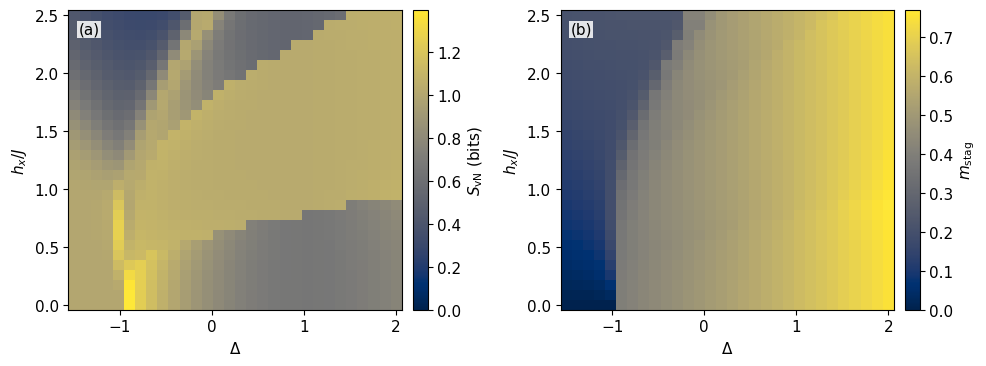

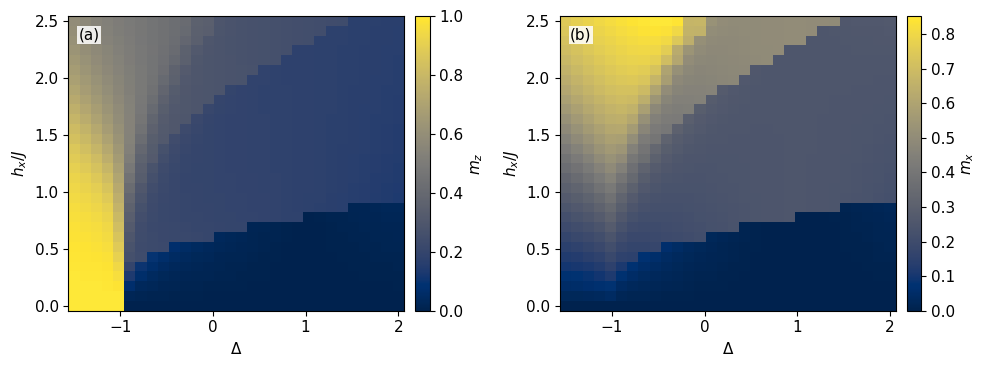

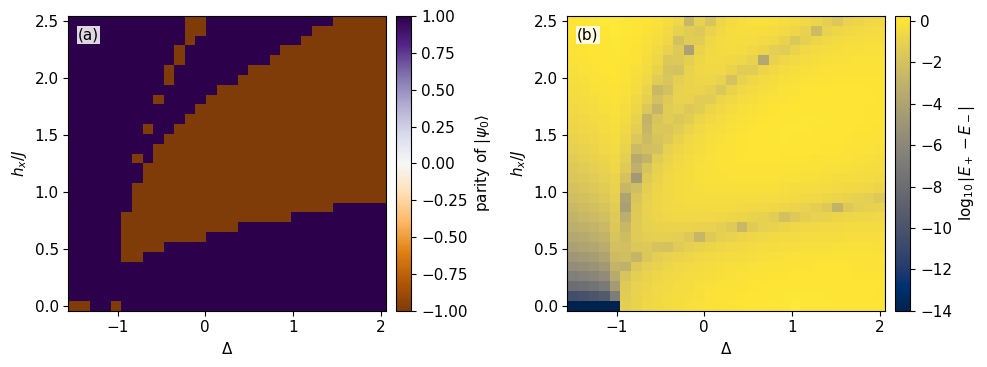

In [4]:
NG_ED = 30
D_AXIS = np.linspace(-1.5, 2.0, NG_ED); H_AXIS = np.linspace(0.0, 2.5, NG_ED)
Dg, Hg = np.meshgrid(D_AXIS, H_AXIS, indexing="ij")            # rows: Delta, columns: h_x
if RETRAIN:
    t_ed = time.perf_counter()
    ED = exact_on_grid(jnp.asarray(Dg.ravel()), jnp.asarray(Hg.ravel()))
    t_ed = time.perf_counter() - t_ed
    print(f"exact ground states of {NG_ED}x{NG_ED} grid points (two parity sectors each) in {t_ed:.1f} s; "
          f"{int(ED['refined'])} sector solutions refined with eigsh")
else:
    stored = np.load(SCAN)
    ED = {k[3:]: stored[k] for k in stored.files if k.startswith("ed_") and k not in ("ed_D_axis", "ed_h_axis")}
    t_ed = float(stored["t_ed"])
    print(f"exact maps loaded from the saved scan (computed in {t_ed:.1f} s in the retraining run)")
assert ED["residual"].max() < 1e-6
print(f"largest residual |H psi - E psi| = {ED['residual'].max():.1e}")

def density(ax, Z2, label, cmap="cividis", vmin=None, vmax=None, Daxis=D_AXIS, Haxis=H_AXIS):
    pcm = ax.pcolormesh(Daxis, Haxis, Z2.T, shading="nearest", cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True)
    cb = plt.colorbar(pcm, ax=ax, fraction=0.05, pad=0.03); cb.set_label(label)
    ax.set_xlabel(r"$\Delta$"); ax.set_ylabel(r"$h_x/J$")
    return pcm

EXACT_MAPS = (("S", r"$S_{\rm vN}$ (bits)"), ("mst", r"$m_{\rm stag}$"), ("mz", r"$m_z$"), ("mx", r"$m_x$"))
fig, axes = plt.subplots(2, 2, figsize=(10.0, 7.6))
for ax, (k, lab), letter in zip(axes.ravel(), EXACT_MAPS, "abcd"):
    density(ax, ED[k].reshape(NG_ED, NG_ED), lab, vmin=0)
    panel(ax, letter)
fig.tight_layout(); save(fig, "fig_lab070a_exact"); plt.close(fig)       # combined version for the notes
for name, maps in (("fig_lab070a_exact_a", EXACT_MAPS[:2]), ("fig_lab070a_exact_b", EXACT_MAPS[2:])):
    fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8))
    for ax, (k, lab), letter in zip(axes, maps, "ab"):
        density(ax, ED[k].reshape(NG_ED, NG_ED), lab, vmin=0)
        panel(ax, letter)
    fig.tight_layout(); save(fig, name); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.8))
density(axes[0], np.where(ED["even"], 1.0, -1.0).reshape(NG_ED, NG_ED), r"parity of $|\psi_0\rangle$", cmap="PuOr", vmin=-1, vmax=1)
density(axes[1], np.log10(np.maximum(ED["split"], 1e-14)).reshape(NG_ED, NG_ED), r"$\log_{10}|E_+-E_-|$")
panel(axes[0], "a"); panel(axes[1], "b")
fig.tight_layout(); save(fig, "fig_lab070a_parity"); plt.show()

def ed_at(D_, h_):
    k = np.argmin(np.abs(D_AXIS - D_)) * NG_ED + np.argmin(np.abs(H_AXIS - h_))
    return {q: float(ED[q][k]) for q in ("S", "mst", "mz", "mx", "split")}
for tag, (D_, h_) in {"Ferro": (-1.5, 0.1), "XY": (0.0, 0.1), "Neel": (2.0, 0.1), "Polarised": (-1.0, 2.5), "NeelField": (2.0, 2.5)}.items():
    r = ed_at(D_, h_)
    print(f"{tag:10s} Delta = {D_:+.1f}, h_x = {h_:.1f}: S = {r['S']:.3f}, m_stag = {r['mst']:.3f}, m_z = {r['mz']:.3f}, m_x = {r['mx']:.3f}, |E+ - E-| = {r['split']:.1e}")
    for q, name in (("S", "S"), ("mst", "Mstag"), ("mz", "Mz"), ("mx", "Mx")):
        NUMBERS[f"Exact{name}{tag}"] = f"{r[q]:.3f}"
NUMBERS["EdGrid"] = str(NG_ED); NUMBERS["EdSeconds"] = f"{t_ed:.0f}"
NUMBERS["OddFraction"] = f"{100 * np.mean(~ED['even']):.0f}"

The ferromagnet occupies the lower left corner. For $\Delta<-1$ and small $h_x$ the order parameter $m_z$ is close to one and the entropy is one bit, as for the cat state $(|0\dots0\rangle+|1\dots1\rangle)/\sqrt2$. There the even and odd levels are split by less than $10^{-8}$, so the ground state is one member of a nearly degenerate doublet. The field polarises the ferromagnet along the upper left of the maps, where $m_x$ grows to about $0.85$ while $m_z$ and the entropy fall. To the right of $\Delta\approx-1$ the staggered magnetisation grows with $\Delta$ and reaches about $0.75$ at $\Delta=2$, below one because quantum fluctuations reduce the Néel order of eight spins. Near $\Delta=0$ at small field the chain is in the XY region, with $m_{\rm stag}\approx0.5$ and an entropy of $0.84$ bits.

On the antiferromagnetic side the field changes the ground state in steps. The parity map shows a wedge of odd ground states, which covers $44\%$ of the grid and is bounded by the lines where the lowest even and odd levels cross, visible as narrow dark lines in the splitting map. The entropy and $m_x$ jump across these lines. These steps are finite-size level crossings of the eight-site chain, whose positions move with $N$, and they are distinct from the phase boundaries of the infinite chain. Up to $h_x=2.5$ the antiferromagnetic side stays far from full polarisation, with $m_x\approx0.26$ at $\Delta=2$.

## 5. Two ansätze

The hardware-efficient ansatz (HEA) [2] starts from $|0\dots0\rangle$ and applies $L$ layers, each a rotation $\hat R_z\hat R_y$ with independent angles on every qubit followed by $\widehat{\rm CZ}$ gates on all neighbouring pairs, and closes with a final block of rotations. With $L=6$ it has $n=2N(L+1)=112$ angles and $(N-1)L=42$ CZ gates. It respects no symmetry of equation (1), so it can reach either parity sector and also states without definite parity.

The Hamiltonian-variational ansatz (HVA) [3, 4] builds its layers from the terms of equation (1), and here every gate carries its own angles, so we call it the HVA with independent angles. On a bond $(i,i+1)$ the coupling terms combine into the two-qubit gate
$$\hat G(\alpha,\beta)=e^{-i\alpha\hat Z_i\hat Z_{i+1}}\,e^{-i\beta(\hat X_i\hat X_{i+1}+\hat Y_i\hat Y_{i+1})} , \tag{6}$$
whose two exponents commute. The angles are written without the factor $1/2$ of the rotation convention $\hat R_{\hat P}(\theta)=e^{-i\theta\hat P/2}$, so $\hat G(\alpha,\beta)=\hat R_{zz}(2\alpha)\hat R_{xx}(2\beta)\hat R_{yy}(2\beta)$. A layer applies $\hat G$ on the even bonds $(0,1),(2,3),(4,5),(6,7)$, then on the odd bonds $(1,2),(3,4),(5,6)$, and finally a field rotation $e^{-i\gamma\hat X_q}=\hat R_x(2\gamma)$ on every qubit $q$. A layer has $2(N-1)+N=22$ angles. With $L=6$ the HVA has $n=132$ angles, close to the 112 of the HEA, and $(N-1)L=42$ two-qubit gates, as many as the HEA. Without the field rotations the same circuit is a symmetry-preserving ansatz for the XXZ chain, which conserves $\sum_i\hat Z_i$, and the field rotations reduce the conserved quantity to the parity $\hat\Pi$. Every factor commutes with the parity (2), so the HVA stays in the parity sector of its initial state. The two sketches below show the building blocks.

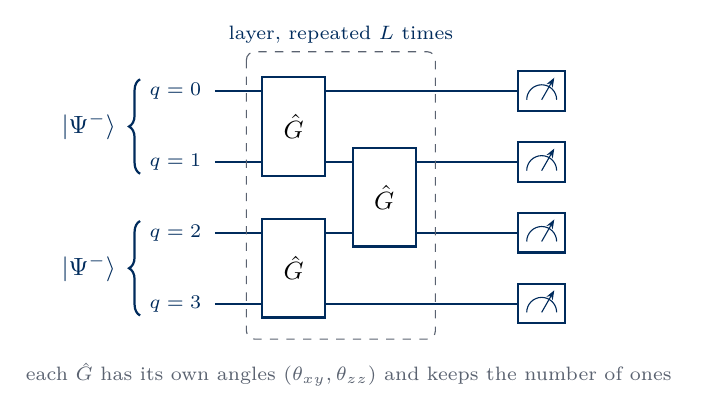

A layer of bond gates on even and then odd bonds, drawn for four qubits from a singlet start, with its own angles $(\theta_{zz},\theta_{xy})=(2\alpha,2\beta)$ in every $\hat G$, is the symmetry-preserving part of the HVA with independent angles.

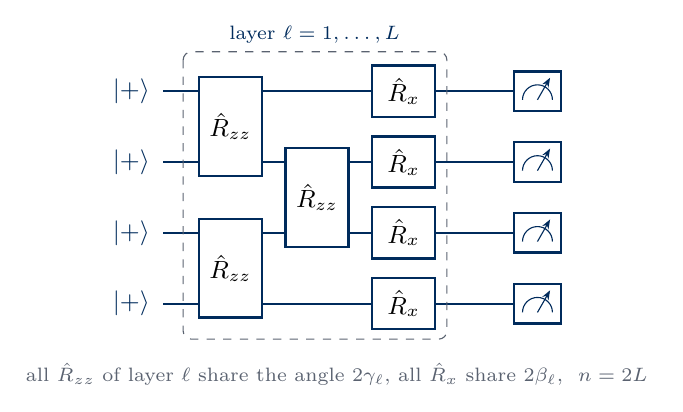

The Hamiltonian-variational layer of the transverse-field Ising chain adds the field rotations $\hat R_x$ after the bond gates with one shared angle per kind of gate, and the HVA with independent angles uses the same layout with $\hat G$ in place of $\hat R_{zz}$ and a separate angle for every gate.

As initial state we take the product of singlets $|\Psi^-\rangle=(|01\rangle-|10\rangle)/\sqrt2$ on the even bonds. It is the ground state of the antiferromagnetic coupling on the even bonds alone, it has $\sum_i\hat Z_i=0$, and since $\hat\Pi|\Psi^-\rangle=-|\Psi^-\rangle$ its parity is $(-1)^4=+1$. To reach odd ground states we also start from $\hat Z_0$ applied to the same product, which turns the first pair into the triplet $|\Psi^+\rangle=(|01\rangle+|10\rangle)/\sqrt2$ with $\hat\Pi|\Psi^+\rangle=+|\Psi^+\rangle$, so that the product has parity $-1$. We train the HVA in both sectors and keep the lower energy, the usual way to handle a conserved quantity whose value in the ground state is unknown. The code checks the gate (6) against the matrix exponential and the parity of both initial states.

In [5]:
L = 6
EVEN_BONDS = [(i, i + 1) for i in range(0, N - 1, 2)]
ODD_BONDS = [(i, i + 1) for i in range(1, N - 1, 2)]
CZ_CHAIN = jnp.asarray(np.prod([(-1.0) ** (BITS[:, q] * BITS[:, q + 1]) for q in range(N - 1)], axis=0).reshape(SHAPE))
ZERO = jnp.zeros(SHAPE, dtype=CDTYPE).at[(0,) * N].set(1.0)

def hea_state(theta):
    th = theta.reshape(L + 1, N, 2)
    def rotations(psi, t):
        for q in range(N):
            psi = apply_1q(psi, rz(t[q, 1]) @ ry(t[q, 0]), q)
        return psi
    psi, _ = jax.lax.scan(lambda p, t: (rotations(p, t) * CZ_CHAIN, None), ZERO, th[:-1])
    return rotations(psi, th[-1])

def bond_gate(a, b):
    # equation (6) in the basis 00, 01, 10, 11
    c, s = jnp.cos(2 * b), jnp.sin(2 * b)
    em, ep = jnp.exp(-1j * a), jnp.exp(1j * a)
    return jnp.array([[em, 0, 0, 0], [0, c * ep, -1j * s * ep, 0], [0, -1j * s * ep, c * ep, 0], [0, 0, 0, em]], dtype=CDTYPE)

from scipy.linalg import expm
assert np.allclose(bond_gate(0.3, 0.7), expm(-0.3j * np.kron(Z, Z)) @ expm(-0.7j * (np.kron(X, X) + np.kron(Y, Y))), atol=TOL)

def hva_state_from(reference):
    def state(theta):
        th = theta.reshape(L, 2 * (N - 1) + N)      # per layer: (alpha, beta) for each bond, gamma for each qubit
        def layer(psi, t):
            for k, (i, j) in enumerate(EVEN_BONDS + ODD_BONDS):
                psi = apply_2q(psi, bond_gate(t[2 * k], t[2 * k + 1]), i, j)
            for q in range(N):
                psi = apply_1q(psi, rx(2 * t[2 * (N - 1) + q]), q)
            return psi, None
        return jax.lax.scan(layer, reference, th)[0]
    return state

singlet = np.array([0, 1, -1, 0]) / np.sqrt(2); triplet = np.array([0, 1, 1, 0]) / np.sqrt(2)
REF_EVEN = jnp.asarray(np.kron(np.kron(np.kron(singlet, singlet), singlet), singlet).reshape(SHAPE).astype(complex))
REF_ODD = apply_1q(REF_EVEN, jnp.asarray(Z), 0)                      # Z on qubit 0 turns the first singlet into a triplet
assert jnp.allclose(REF_ODD, jnp.asarray(np.kron(np.kron(np.kron(triplet, singlet), singlet), singlet).reshape(SHAPE)), atol=TOL)
for ref, sign in ((REF_EVEN, 1.0), (REF_ODD, -1.0)):
    assert jnp.allclose(flip_all(ref), sign * ref, atol=TOL)
th_r = jax.random.normal(jax.random.PRNGKey(7001), (L * (2 * (N - 1) + N),))
psi_r = hva_state_from(REF_ODD)(th_r)
assert jnp.allclose(flip_all(psi_r), -psi_r, atol=1e-9)              # the HVA keeps the parity of its initial state
ANSATZ = {"HEA": dict(n=2 * N * (L + 1), two_qubit=(N - 1) * L), "HVA": dict(n=L * (2 * (N - 1) + N), two_qubit=(N - 1) * L)}
print(ANSATZ)

{'HEA': {'n': 112, 'two_qubit': 42}, 'HVA': {'n': 132, 'two_qubit': 42}}


## 6. Training on the grid

At every grid point VQE minimises $E(\boldsymbol\theta)=\langle\psi(\boldsymbol\theta)|\hat{\mathcal H}|\psi(\boldsymbol\theta)\rangle$, evaluated with the matrix-free Hamiltonian of Section 3. The gradient comes from automatic differentiation with `jax.grad`. On a device each partial derivative would require two shifted circuits by the parameter-shift rule [5, 6], each measured in the three settings that estimate the $\hat X\hat X$, $\hat Y\hat Y$ and $\hat Z\hat Z$ terms (the field term shares the all-$x$ setting). Each estimate carries a statistical error from the finite number of shots. The cost counts parametrised Pauli rotations, 112 for the HEA and $L(3(N-1)+N)=174$ for the HVA, since $\beta$ enters both $\hat R_{xx}$ and $\hat R_{yy}$ in every gate (6).

We update the angles with the Adam optimiser [7], written in a few lines, for 300 iterations with learning rate $0.05$. Every grid point is trained independently, and both ansätze receive the same budget of two starts per point. The HVA starts once in each parity sector from angles drawn from a normal distribution of width $0.1$ around its initial state. The HEA starts once from such small angles near $|0\dots0\rangle$ and once from angles drawn uniformly from $[-\pi,\pi)$, and we keep the start with the lower energy. Independent starts keep the grid points from influencing each other and keep a failure at one point from spreading along the scan. One compiled function applies `jax.vmap` over all grid points and `jax.lax.scan` over the iterations and the layers. The VQE grid has $20\times 20$ points over the same range as the exact maps, and the exact ground states at these points come from the Lanczos function of Section 4. The trained angles and all observables are saved to a file, so the maps can be redrawn without training.

In [6]:
NG_VQE = 20
STEPS, LR, RESTARTS = 300, 0.05, 1          # RESTARTS per HVA sector; the HEA gets two starts
DV_AXIS = np.linspace(-1.5, 2.0, NG_VQE); HV_AXIS = np.linspace(0.0, 2.5, NG_VQE)
DVg, HVg = np.meshgrid(DV_AXIS, HV_AXIS, indexing="ij")
Dv, Hv = jnp.asarray(DVg.ravel()), jnp.asarray(HVg.ravel())
if RETRAIN:
    EXV = exact_on_grid(Dv, Hv)
    psi0_v = jnp.asarray(EXV["psi0"])
else:
    EXV = {k[6:]: stored[k] for k in stored.files if k.startswith("exact_")}

def make_grid_trainer(state_fn):
    def energy(theta, Delta, hx):
        psi = state_fn(theta)
        return jnp.real(jnp.vdot(psi, xxz_apply(psi, Delta, hx)))
    grad = jax.vmap(jax.vmap(jax.grad(energy), in_axes=(0, None, None)), in_axes=(0, 0, 0))
    def final(theta, Delta, hx, psi0):
        psi = state_fn(theta).reshape(-1)
        return (*observables(psi, Delta, hx), jnp.abs(jnp.vdot(psi0, psi)) ** 2)
    final_v = jax.vmap(jax.vmap(final, in_axes=(0, None, None, None)), in_axes=(0, 0, 0, 0))
    b1, b2, eps = 0.9, 0.999, 1e-8
    @jax.jit
    def run(theta0, Ds, hs, psi0s):
        def step(carry, t):
            theta, m, v = carry
            g = grad(theta, Ds, hs)
            m = b1 * m + (1 - b1) * g
            v = b2 * v + (1 - b2) * g ** 2
            theta = theta - LR * (m / (1 - b1 ** t)) / (jnp.sqrt(v / (1 - b2 ** t)) + eps)
            return (theta, m, v), None
        zeros = jnp.zeros_like(theta0)
        (theta, _, _), _ = jax.lax.scan(step, (theta0, zeros, zeros), jnp.arange(1, STEPS + 1))
        return theta, final_v(theta, Ds, hs, psi0s)
    return run

def best_restart(out):
    theta, (E, mx, mst, mz, S, F) = out
    E = np.asarray(E); b = np.argmin(E, axis=1); ix = np.arange(E.shape[0])
    return dict(theta=np.asarray(theta)[ix, b], E=E[ix, b], mx=np.asarray(mx)[ix, b], mst=np.asarray(mst)[ix, b],
                mz=np.asarray(mz)[ix, b], S=np.asarray(S)[ix, b], F=np.asarray(F)[ix, b])

VQE, TIMES = {}, {}
P = Dv.size
if RETRAIN:
    key, k1, k2, k3, k4 = jax.random.split(key, 5)
    t0 = time.perf_counter()
    theta0_hea = jnp.concatenate([0.1 * jax.random.normal(k1, (P, 1, ANSATZ["HEA"]["n"])),                 # near |0...0>
                                  jax.random.uniform(k4, (P, 1, ANSATZ["HEA"]["n"]), minval=-np.pi, maxval=np.pi)], axis=1)
    VQE["HEA"] = best_restart(make_grid_trainer(hea_state)(theta0_hea, Dv, Hv, psi0_v))
    TIMES["HEA"] = time.perf_counter() - t0
    sectors = {}
    for name, ref, kk in (("even", REF_EVEN, k2), ("odd", REF_ODD, k3)):
        t0 = time.perf_counter()
        sectors[name] = best_restart(make_grid_trainer(hva_state_from(ref))(0.1 * jax.random.normal(kk, (P, RESTARTS, ANSATZ["HVA"]["n"])), Dv, Hv, psi0_v))
        TIMES[f"HVA {name}"] = time.perf_counter() - t0
    odd_wins = sectors["odd"]["E"] < sectors["even"]["E"]
    VQE["HVA"] = {k: np.where(odd_wins.reshape((-1,) + (1,) * (sectors["even"][k].ndim - 1)), sectors["odd"][k], sectors["even"][k])
                  for k in sectors["even"]}
    VQE["HVA"]["odd"] = odd_wins
    np.savez_compressed(SCAN, D_axis=DV_AXIS, h_axis=HV_AXIS, ed_D_axis=D_AXIS, ed_h_axis=H_AXIS, t_ed=t_ed,
                        **{f"time_{k.replace(' ', '_')}": v for k, v in TIMES.items()},
                        **{f"ed_{k}": v for k, v in ED.items() if k not in ("psi0", "refined")},
                        **{f"exact_{k}": v for k, v in EXV.items() if k not in ("psi0", "refined")},
                        **{f"{a}_{k}": v for a in VQE for k, v in VQE[a].items()})
else:
    VQE = {a: {k[len(a) + 1:]: stored[k] for k in stored.files if k.startswith(a + "_")} for a in ("HEA", "HVA")}
    TIMES = {k[5:].replace("_", " "): float(stored[k]) for k in stored.files if k.startswith("time_")}
odd_wins = VQE["HVA"]["odd"]
for a in ("HEA", "HVA"):
    assert np.all(VQE[a]["E"] >= EXV["E0"] - 1e-9)                    # variational principle at every point
t_vqe = sum(TIMES.values())
print({k: f"{v:.1f} s" for k, v in TIMES.items()}, f"| VQE total {t_vqe:.1f} s for {NG_VQE}x{NG_VQE} points",
      "(measured in the retraining run)" if not RETRAIN else "")
print(f"HVA sector choice agrees with the exact ground-state parity at {np.mean(odd_wins == ~EXV['even']) * 100:.0f}% of the points")

{'HEA': '112.6 s', 'HVA even': '75.7 s', 'HVA odd': '84.2 s'} | VQE total 272.5 s for 20x20 points (measured in the retraining run)
HVA sector choice agrees with the exact ground-state parity at 96% of the points


## 7. Where each ansatz fails

The figure maps, for the HEA (top row) and the HVA (bottom row), the logarithm of the relative energy error $\delta E=(E-E_0)/|E_0|$ (left), the logarithm of the infidelity $1-F$ (middle) and the entropy error $\delta S=|S_{\rm vN}-S_{\rm vN}^{\rm exact}|$ in bits (right). Dark colours mark small errors.

Ferro  ( 15 points): HEA: median dE 1.4e-05, F 0.500, dS 1.000 | HVA: median dE 2.2e-05, F 0.000, dS 0.000
XY     ( 45 points): HEA: median dE 1.3e-02, F 0.912, dS 0.274 | HVA: median dE 2.5e-04, F 0.999, dS 0.008
Neel   ( 20 points): HEA: median dE 1.3e-02, F 0.963, dS 0.213 | HVA: median dE 7.5e-05, F 1.000, dS 0.003
Field  (100 points): HEA: median dE 9.9e-03, F 0.686, dS 0.441 | HVA: median dE 6.7e-04, F 0.999, dS 0.014
HEA: median dE over the grid 1.2e-02, F > 0.99 at 5% of the points
HVA: median dE over the grid 5.7e-04, F > 0.99 at 94% of the points
HEA points with dE < 1e-3 but F < 0.6: 34 of 400


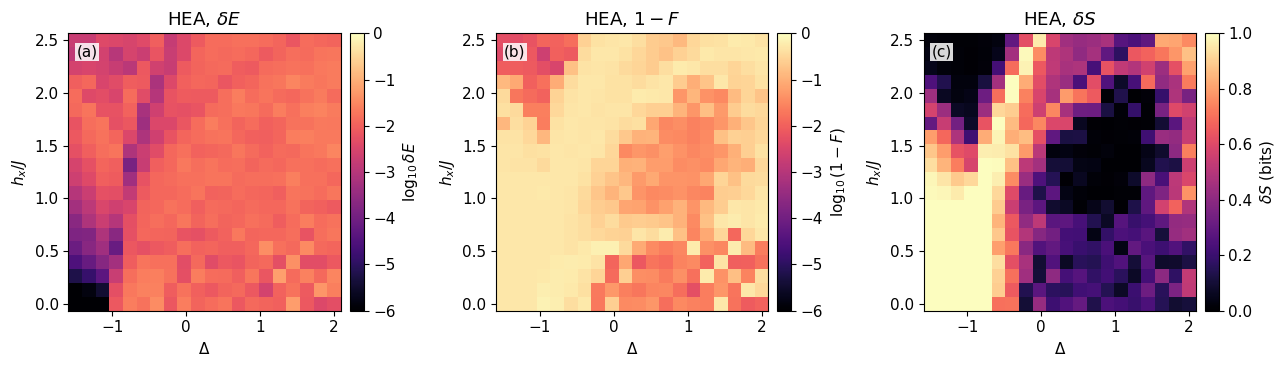

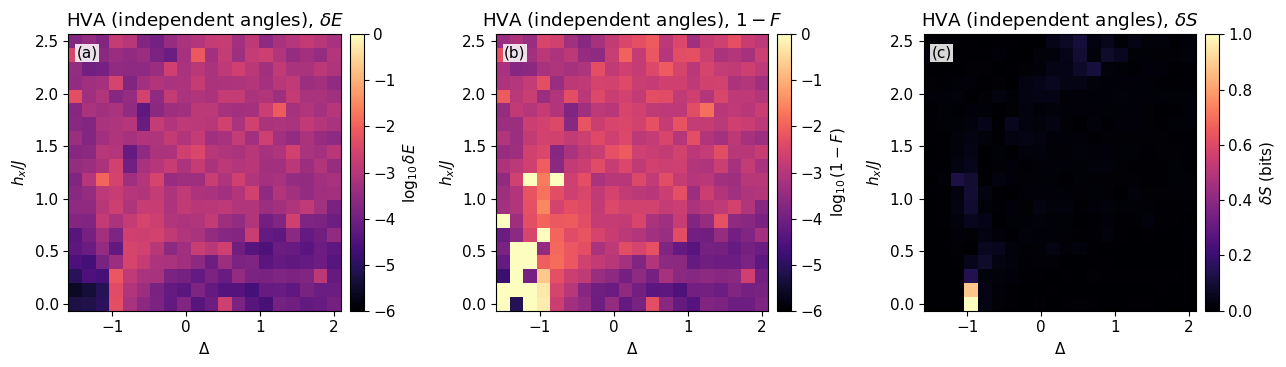

In [7]:
E0v = EXV["E0"]
def error_maps(a):
    r = VQE[a]
    dE = np.log10(np.maximum((r["E"] - E0v) / np.abs(E0v), 1e-10))
    inf = np.log10(np.maximum(1 - r["F"], 1e-10))
    dS = np.abs(r["S"] - EXV["S"])
    return ((dE, r"$\log_{10}\delta E$", (-6, 0)), (inf, r"$\log_{10}(1-F)$", (-6, 0)), (dS, r"$\delta S$ (bits)", (0, 1)))
NAMES = {"HEA": "HEA", "HVA": "HVA (independent angles)"}
fig, axes = plt.subplots(2, 3, figsize=(13.0, 7.4))            # combined version for the notes
for row, a in enumerate(("HEA", "HVA")):
    for col, (Z2, lab, lims) in enumerate(error_maps(a)):
        density(axes[row, col], Z2.reshape(NG_VQE, NG_VQE), lab, cmap="magma", vmin=lims[0], vmax=lims[1], Daxis=DV_AXIS, Haxis=HV_AXIS)
        panel(axes[row, col], "abcdef"[3 * row + col])
        if row == 0:
            axes[row, col].set_title((r"$\delta E$", r"$1-F$", r"$\delta S$")[col])
    axes[row, 0].annotate(NAMES[a], xy=(-0.42, 0.5), xycoords="axes fraction", rotation=90, ha="center", va="center")
fig.tight_layout(rect=(0.03, 0, 1, 1)); save(fig, "fig_lab070a_ansatz_errors"); plt.close(fig)
for a, name in (("HEA", "fig_lab070a_ansatz_errors_hea"), ("HVA", "fig_lab070a_ansatz_errors_hva")):
    fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.8))
    for col, (Z2, lab, lims) in enumerate(error_maps(a)):
        density(axes[col], Z2.reshape(NG_VQE, NG_VQE), lab, cmap="magma", vmin=lims[0], vmax=lims[1], Daxis=DV_AXIS, Haxis=HV_AXIS)
        panel(axes[col], "abc"[col]); axes[col].set_title(f"{NAMES[a]}, " + (r"$\delta E$", r"$1-F$", r"$\delta S$")[col])
    fig.tight_layout(); save(fig, name); plt.show()

def region(mask):
    return {a: dict(dE=float(np.median((VQE[a]["E"][mask] - E0v[mask]) / np.abs(E0v[mask]))), F=float(np.median(VQE[a]["F"][mask])),
                    dS=float(np.median(np.abs(VQE[a]["S"][mask] - EXV["S"][mask])))) for a in VQE}
REGIONS = {"Ferro": (DVg.ravel() < -1.05) & (HVg.ravel() < 0.6),
           "XY": (np.abs(DVg.ravel()) < 0.8) & (HVg.ravel() < 0.6),
           "Neel": (DVg.ravel() > 1.3) & (HVg.ravel() < 0.6),
           "Field": HVg.ravel() > 1.9}
REG = {k: region(m) for k, m in REGIONS.items()}
for k, v in REG.items():
    print(f"{k:6s} ({REGIONS[k].sum():3d} points): " + " | ".join(f"{a}: median dE {v[a]['dE']:.1e}, F {v[a]['F']:.3f}, dS {v[a]['dS']:.3f}" for a in v))
    for a in v:
        A = a.capitalize()
        NUMBERS[f"Median{A}RelErr{k}"] = sci(v[a]["dE"]); NUMBERS[f"Median{A}Fid{k}"] = f"{v[a]['F']:.3f}"; NUMBERS[f"Median{A}DS{k}"] = f"{v[a]['dS']:.2f}"
for a in VQE:
    A = a.capitalize()
    NUMBERS[f"Median{A}RelErr"] = sci(float(np.median((VQE[a]["E"] - E0v) / np.abs(E0v))))
    NUMBERS[f"Frac{A}FidAbove"] = f"{100 * np.mean(VQE[a]['F'] > 0.99):.0f}"
    print(f"{a}: median dE over the grid {np.median((VQE[a]['E'] - E0v) / np.abs(E0v)):.1e}, F > 0.99 at {100 * np.mean(VQE[a]['F'] > 0.99):.0f}% of the points")
low_dE_bad_F = ((VQE["HEA"]["E"] - E0v) / np.abs(E0v) < 1e-3) & (VQE["HEA"]["F"] < 0.6)
print(f"HEA points with dE < 1e-3 but F < 0.6: {low_dE_bad_F.sum()} of {low_dE_bad_F.size}")
NUMBERS["HeaLowErrBadFid"] = str(int(low_dE_bad_F.sum())); NUMBERS["VqeGrid"] = str(NG_VQE); NUMBERS["VqePoints"] = str(P)
NUMBERS["Layers"] = str(L); NUMBERS["Steps"] = str(STEPS); NUMBERS["ParamsHea"] = str(ANSATZ["HEA"]["n"]); NUMBERS["ParamsHva"] = str(ANSATZ["HVA"]["n"])
NUMBERS["TwoQubitGates"] = str(ANSATZ["HEA"]["two_qubit"]); NUMBERS["VqeSeconds"] = f"{t_vqe:.0f}"

The HVA with independent angles reaches $F>0.99$ at $94\%$ of the grid points, with relative energy errors between about $10^{-5}$ and $10^{-3}$ and entropy errors of about a hundredth of a bit. It finds the ground state in the odd wedge as well, because there the two parity runs differ in energy by far more than their training errors. It fails in the lower left corner and along $\Delta\approx-1$, where the parity splitting is smaller than its energy error and the lower of the two trained energies can belong to the other sector. In the ferromagnetic corner the fidelity with the chosen exact state then drops to zero. The energy error stays near $10^{-5}$ and the entropy is correct, since the two members of the doublet share their energy and their entanglement to this accuracy. Next to $\Delta=-1$ at the two smallest fields, where several levels lie close together, the entropy error reaches about one bit. Elsewhere the HVA does well because its gates are the terms of the Hamiltonian, it starts from singlets with the antiferromagnetic correlations of the low-field ground states, and it never mixes the parity sectors.

The HEA reaches $F>0.99$ at only $5\%$ of the points, and its median fidelity is about $0.9$ in the XY region, $0.96$ in the Néel region and $0.7$ at the largest fields. Deep in the ferromagnet it has the smallest energy errors of the map, near $10^{-5}$, together with $F=1/2$ and an entropy error of one bit. It prepares one of the two aligned configurations, a symmetry-broken branch of the doublet. Elsewhere its energy error stays near $10^{-2}$ and its entropy lies below the exact value at most points, so with two starts and 300 iterations it builds too little of the entanglement of the critical and antiferromagnetic ground states. At 34 of the 400 points the HEA has $\delta E<10^{-3}$ and $F<0.6$, so a small energy error does not certify the trained state.

## 8. A cut through the Néel phase

At fixed anisotropy, in the column of the VQE grid closest to $\Delta=1.5$, the figure shows the entanglement entropy (a), the staggered magnetisation (b) and the infidelity (c) of both ansätze against $h_x$. Black lines are the exact values on the same grid.

cut at Delta = 1.447


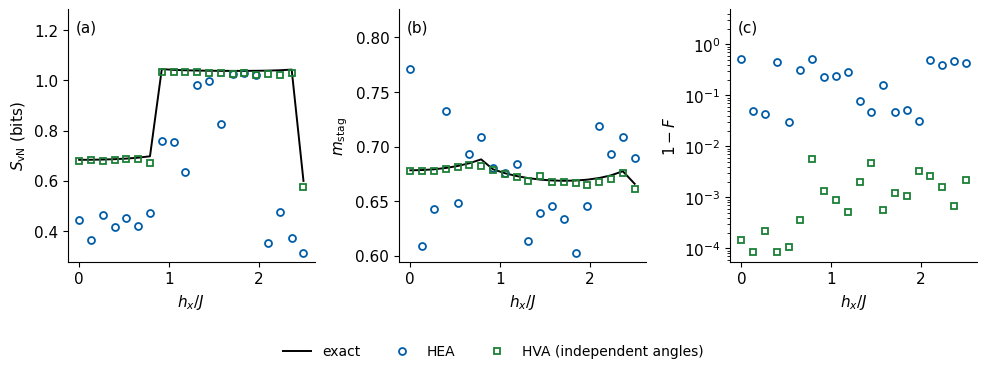

In [8]:
col = int(np.argmin(np.abs(DV_AXIS - 1.5)))
sel = np.arange(NG_VQE) + col * NG_VQE
fig, axes = plt.subplots(1, 3, figsize=(10.0, 3.6))
axes[0].plot(HV_AXIS, EXV["S"][sel], "k-", lw=1.4, label="exact")
axes[1].plot(HV_AXIS, EXV["mst"][sel], "k-", lw=1.4)
for a, mk in (("HEA", "o"), ("HVA", "s")):
    kw = dict(ls="none", marker=mk, ms=5, mfc="none", mew=1.3, color=COL[a])
    axes[0].plot(HV_AXIS, VQE[a]["S"][sel], label={"HEA": "HEA", "HVA": "HVA (independent angles)"}[a], **kw)
    axes[1].plot(HV_AXIS, VQE[a]["mst"][sel], **kw)
    axes[2].semilogy(HV_AXIS, np.maximum(1 - VQE[a]["F"][sel], 1e-8), **kw)
for ax, lab, letter in zip(axes, (r"$S_{\rm vN}$ (bits)", r"$m_{\rm stag}$", r"$1-F$"), "abc"):
    ax.set_xlabel(r"$h_x/J$"); ax.set_ylabel(lab); panel(ax, letter)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes[:2]:
    lo, hi = ax.get_ylim(); ax.set_ylim(lo, hi + 0.25 * (hi - lo))   # room for the panel labels
lo, hi = axes[2].get_ylim(); axes[2].set_ylim(lo, hi * 6)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=10, frameon=False, bbox_to_anchor=(0.5, -0.05))
fig.tight_layout(rect=(0, 0.07, 1, 1)); save(fig, "fig_lab070a_cut"); plt.show()
print(f"cut at Delta = {DV_AXIS[col]:.3f}")
NUMBERS["CutDelta"] = f"{DV_AXIS[col]:.2f}"

Along the cut the exact entropy jumps twice, near $h_x\approx0.9$ and $h_x\approx2.4$, where the ground state changes its parity sector, and stays almost constant between the jumps. The staggered magnetisation changes only weakly, so the Néel correlations persist over this range of fields. The HVA follows both curves, including the jumps, since it is trained in each sector separately, and its infidelity stays between $10^{-4}$ and $10^{-2}$. The HEA scatters around the exact curves, with infidelities between $0.03$ and $0.52$ and an entropy below the exact value at every field of the cut.

In [9]:
runtime = time.perf_counter() - started
NUMBERS["Runtime"] = f"{runtime:.0f}"; NUMBERS["RuntimeMinutes"] = f"{runtime / 60:.1f}"
NUMBERS["HeaStarts"] = "2"; NUMBERS["HvaStarts"] = "2"
summary = dict(experiment="VQE phase diagram of the XXZ chain in a transverse field, exact state-vector simulation and exact gradients",
               N=N, J=1.0, layers=L, steps=STEPS, learning_rate=LR, restarts=RESTARTS, starts="independent per grid point and sector",
               ed_grid=dict(Delta=D_AXIS.tolist(), h_x=H_AXIS.tolist(), seconds=t_ed, krylov=KRYLOV),
               vqe_grid=dict(Delta=DV_AXIS.tolist(), h_x=HV_AXIS.tolist(), seconds=TIMES),
               ansatz=ANSATZ, starts_per_point={"HEA": "small angles near |0...0> and uniform random angles", "HVA": "one per parity sector"}, regions=REG, odd_ground_state_fraction=float(np.mean(~ED["even"])),
               hea_low_error_bad_fidelity=int(low_dE_bad_F.sum()), scan_file="classroom_results/lab070a_scan.npz",
               retrain=RETRAIN, runtime_seconds=runtime)
if RETRAIN:   # the stored results and macros always come from a retraining run
    (RES / "lab070a_results.json").write_text(json.dumps(summary, indent=2))
    with open(FIG / "nb_numbers_lab070a.tex", "w") as f:
        for k, v in NUMBERS.items():
            assert k.isalpha(), k
            f.write(f"\\newcommand{{\\labseventyA{k}}}{{{v.strip()}}}\n")
print("numbers:", NUMBERS)
print(f"runtime {runtime:.1f} s")

numbers: {'ExactSFerro': '1.000', 'ExactMstagFerro': '0.011', 'ExactMzFerro': '1.000', 'ExactMxFerro': '0.024', 'ExactSXY': '0.841', 'ExactMstagXY': '0.494', 'ExactMzXY': '0.004', 'ExactMxXY': '0.003', 'ExactSNeel': '0.760', 'ExactMstagNeel': '0.749', 'ExactMzNeel': '0.002', 'ExactMxNeel': '0.002', 'ExactSPolarised': '0.319', 'ExactMstagPolarised': '0.218', 'ExactMzPolarised': '0.505', 'ExactMxPolarised': '0.813', 'ExactSNeelField': '1.063', 'ExactMstagNeelField': '0.749', 'ExactMzNeelField': '0.164', 'ExactMxNeelField': '0.263', 'EdGrid': '30', 'EdSeconds': '41', 'OddFraction': '44', 'MedianHeaRelErrFerro': '1.4\\times10^{-5}', 'MedianHeaFidFerro': '0.500', 'MedianHeaDSFerro': '1.00', 'MedianHvaRelErrFerro': '2.2\\times10^{-5}', 'MedianHvaFidFerro': '0.000', 'MedianHvaDSFerro': '0.00', 'MedianHeaRelErrXY': '1.3\\times10^{-2}', 'MedianHeaFidXY': '0.912', 'MedianHeaDSXY': '0.27', 'MedianHvaRelErrXY': '2.5\\times10^{-4}', 'MedianHvaFidXY': '0.999', 'MedianHvaDSXY': '0.01', 'MedianHeaRelE

## 9. Exercises

1. Show that $\hat\Pi$ of equation (2) commutes with each term of equation (1), using $\hat X\hat Y\hat X=-\hat Y$ and $\hat X\hat Z\hat X=-\hat Z$.
2. Replace the transverse field by a longitudinal one, $-h_z\sum_i\hat Z_i$. Show that $\sum_i\hat Z_i$ is then conserved, compute the exact ground-state magnetisation as a function of $h_z$ at $\Delta=0.5$, and observe its steps. Train a symmetry-preserving ansatz (the HVA without the field rotation) from the singlet product, which has $\sum_i\hat Z_i=0$, and explain why it cannot reach the ground state once that state lies in another magnetisation sector.
3. Start the HVA from $|+\rangle^{\otimes N}$ and from $\hat Z_0|+\rangle^{\otimes N}$, and compare the error maps with those of the singlet references on the ferromagnetic side.
4. Repeat the scan with warm starts, sweeping $h_x$ from $2.5$ down to $0$ at each $\Delta$ and starting every point from the trained angles of its neighbour, and compare the HEA fidelity in the ordered regions.
5. Use the parity-splitting map to predict where the HEA fidelity is close to $1/2$, and check the prediction against the error maps.
6. Estimate the number of circuit executions that one HEA gradient would need on a device with the parameter-shift rule, three measurement settings and $1000$ shots per setting.

## 10. Summary

The XXZ chain in a transverse field conserves only the parity of all bits. On eight sites its ground state changes from a ferromagnetic cat state through the XY region to Néel-like states. It approaches the field-polarised state on the ferromagnetic side, and on the antiferromagnetic side it crosses between the two parity sectors as the field grows. A Lanczos diagonalisation that applies the Hamiltonian term by term gives the exact maps on a fine grid. A Hamiltonian-variational ansatz with independent angles, started from singlet products in both parity sectors, prepares the ground state with fidelity above 0.99 almost everywhere and fails only where the two sectors are nearly degenerate. The hardware-efficient ansatz with the same number of two-qubit gates reaches small energy errors only in the ferromagnet, where it breaks the symmetry, and misses the entanglement elsewhere. A small energy error therefore does not certify the trained state, whereas the fidelity and the entanglement entropy reveal the failures. Both ansätze ran with the same budget, six layers with 42 two-qubit gates, two starts per grid point and 300 Adam iterations per start, and the conclusions hold for this budget.

### References

1. A. Peruzzo, J. McClean, P. Shadbolt, M.-H. Yung, X.-Q. Zhou, P. J. Love, A. Aspuru-Guzik, and J. L. O'Brien, A variational eigenvalue solver on a photonic quantum processor, Nat. Commun. **5**, 4213 (2014), [doi:10.1038/ncomms5213](https://doi.org/10.1038/ncomms5213).
2. A. Kandala, A. Mezzacapo, K. Temme, M. Takita, M. Brink, J. M. Chow, and J. M. Gambetta, Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets, Nature **549**, 242 (2017), [doi:10.1038/nature23879](https://doi.org/10.1038/nature23879).
3. D. Wecker, M. B. Hastings, and M. Troyer, Progress towards practical quantum variational algorithms, Phys. Rev. A **92**, 042303 (2015), [doi:10.1103/PhysRevA.92.042303](https://doi.org/10.1103/PhysRevA.92.042303).
4. R. Wiersema, C. Zhou, Y. de Sereville, J. F. Carrasquilla, Y. B. Kim, and H. Yuen, Exploring entanglement and optimization within the Hamiltonian variational ansatz, PRX Quantum **1**, 020319 (2020), [doi:10.1103/PRXQuantum.1.020319](https://doi.org/10.1103/PRXQuantum.1.020319).
5. K. Mitarai, M. Negoro, M. Kitagawa, and K. Fujii, Quantum circuit learning, Phys. Rev. A **98**, 032309 (2018), [doi:10.1103/PhysRevA.98.032309](https://doi.org/10.1103/PhysRevA.98.032309).
6. M. Schuld, V. Bergholm, C. Gogolin, J. Izaac, and N. Killoran, Evaluating analytic gradients on quantum hardware, Phys. Rev. A **99**, 032331 (2019), [doi:10.1103/PhysRevA.99.032331](https://doi.org/10.1103/PhysRevA.99.032331).
7. D. P. Kingma and J. Ba, Adam: A method for stochastic optimization, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980) (2014).